<a href="https://colab.research.google.com/github/annaannaR/vivino-final-project-amsterdam-data-academy/blob/main/Final_Project_%E2%80%93_Vivino_Anna_Rogiewicz.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import unicodedata
import csv

from sklearn.preprocessing import StandardScaler
from io import StringIO

# make sure that plots are visible in this notebook
%matplotlib inline

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# Data cleaning

In [ ]:
sheets = pd.read_excel("/Vivino-export.xlsx", engine="openpyxl", sheet_name=None)

dfs = []

for sheet_name, df_raw in sheets.items():
    if df_raw.empty:
        continue

    text = "\n".join(df_raw.iloc[:, 0].dropna().astype(str))

    df_part = pd.read_csv(
        StringIO(text),
        sep=",",
        engine="python",
        quoting=csv.QUOTE_MINIMAL,
        on_bad_lines="skip"
    )

    df_part.columns = ["name", "country", "region", "rating", "rating_count", "price"]
    df_part["sheet"] = sheet_name
    dfs.append(df_part)

df = pd.concat(dfs, ignore_index=True)

def normalize_text(text):
    text = unicodedata.normalize('NFKD', text)
    return text.encode('ascii', 'ignore').decode('utf-8')

for col in ["name", "country", "region"]:
    df[col] = df[col].apply(lambda x: normalize_text(x) if isinstance(x, str) else x)

df.head()

,name,country,region,rating,rating_count,price,sheet
0,Caiarossa Aria di Caiarossa 2015,"('Itali ',)","('Toscane',)",4.2,506,28.047878,Italie
1,Martin Tesch Unplugged Riesling 2019,"('Duitsland',)","('Nahe',)",3.7,129,10.287832,Italie
2,Azienda Agricola I Luoghi Podere Ritorti Bolgh...,"('Itali ',)","('Bolgheri Superiore',)",4.2,63,28.697636,Italie
3,Caiarossa Aria di Caiarossa 2015,"('Itali ',)","('Toscane',)",4.2,504,28.088608,Uruguay
4,Martin Tesch Unplugged Riesling 2019,"('Duitsland',)","('Nahe',)",3.7,129,10.302771,Uruguay


In [ ]:
df.country.value_counts()

,count
country,
"('Frankrijk',)",192868
"('Itali ',)",77366
"('Spanje',)",35600
"('Australi ',)",31138
"('Portugal',)",15415
"('Verenigde Staten',)",13154
"('Argentini ',)",12099
"('Chili',)",11500
"('Duitsland',)",4718


In [ ]:
df.country = df.country.astype(str).str.replace(r"[()'√´,]","", regex=True)
df.region = df.region.astype(str).str.replace(r"[()'√´,]","", regex=True)
df.country = df.country.astype(str).str.replace(r"[()'√´,]","", regex=True)
df

,name,country,region,rating,rating_count,price,sheet
0,Caiarossa Aria di Caiarossa 2015,Itali,Toscane,4.2,506,28.047878,Italie
1,Martin Tesch Unplugged Riesling 2019,Duitsland,Nahe,3.7,129,10.287832,Italie
2,Azienda Agricola I Luoghi Podere Ritorti Bolgh...,Itali,Bolgheri Superiore,4.2,63,28.697636,Italie
3,Caiarossa Aria di Caiarossa 2015,Itali,Toscane,4.2,504,28.088608,Uruguay
4,Martin Tesch Unplugged Riesling 2019,Duitsland,Nahe,3.7,129,10.302771,Uruguay
...,...,...,...,...,...,...,...
409737,Cremaschi Furlotti Cabernet Sauvignon Reserva ...,Chili,Valle del Loncomilla,3.4,235,11.577249,New Zealand
409738,Vergelegen Sauvignon Blanc 2019,Zuid-Afrika,Stellenbosch,3.6,145,21.419927,New Zealand
409739,Vergelegen Cabernet Sauvignon - Merlot 2017,Zuid-Afrika,Stellenbosch,4.0,145,21.419927,New Zealand
409740,Clearwater Cove Sauvignon Blanc Ros 2020,New Zealand,Marlborough,3.9,111,13.029447,New Zealand


In [ ]:
df.country.value_counts()

,count
country,
Frankrijk,192868
Itali,77366
Spanje,35600
Australi,31138
Portugal,15415
Verenigde Staten,13154
Argentini,12099
Chili,11500
Duitsland,4718


In [ ]:
df.region.value_counts()

,count
region,
Grand cru Saint-amilion,20878
Champagne,19529
Pauillac,15857
Margaux,13952
Saint-Estphe,12406
...,...
New York,1
Brachetto dAoAcqui,1
Bourgogne Mousseux,1


In [ ]:
df["year"] = df.name.str.extract(r"(\d{4})")
df

,name,country,region,rating,rating_count,price,sheet,year
0,Caiarossa Aria di Caiarossa 2015,Itali,Toscane,4.2,506,28.047878,Italie,2015
1,Martin Tesch Unplugged Riesling 2019,Duitsland,Nahe,3.7,129,10.287832,Italie,2019
2,Azienda Agricola I Luoghi Podere Ritorti Bolgh...,Itali,Bolgheri Superiore,4.2,63,28.697636,Italie,2018
3,Caiarossa Aria di Caiarossa 2015,Itali,Toscane,4.2,504,28.088608,Uruguay,2015
4,Martin Tesch Unplugged Riesling 2019,Duitsland,Nahe,3.7,129,10.302771,Uruguay,2019
...,...,...,...,...,...,...,...,...
409737,Cremaschi Furlotti Cabernet Sauvignon Reserva ...,Chili,Valle del Loncomilla,3.4,235,11.577249,New Zealand,2017
409738,Vergelegen Sauvignon Blanc 2019,Zuid-Afrika,Stellenbosch,3.6,145,21.419927,New Zealand,2019
409739,Vergelegen Cabernet Sauvignon - Merlot 2017,Zuid-Afrika,Stellenbosch,4.0,145,21.419927,New Zealand,2017
409740,Clearwater Cove Sauvignon Blanc Ros 2020,New Zealand,Marlborough,3.9,111,13.029447,New Zealand,2020


In [ ]:
df.name = df.name.replace(r"\s*\d{4}$", "", regex=True)
df

,name,country,region,rating,rating_count,price,sheet,year
0,Caiarossa Aria di Caiarossa,Itali,Toscane,4.2,506,28.047878,Italie,2015
1,Martin Tesch Unplugged Riesling,Duitsland,Nahe,3.7,129,10.287832,Italie,2019
2,Azienda Agricola I Luoghi Podere Ritorti Bolgh...,Itali,Bolgheri Superiore,4.2,63,28.697636,Italie,2018
3,Caiarossa Aria di Caiarossa,Itali,Toscane,4.2,504,28.088608,Uruguay,2015
4,Martin Tesch Unplugged Riesling,Duitsland,Nahe,3.7,129,10.302771,Uruguay,2019
...,...,...,...,...,...,...,...,...
409737,Cremaschi Furlotti Cabernet Sauvignon Reserva,Chili,Valle del Loncomilla,3.4,235,11.577249,New Zealand,2017
409738,Vergelegen Sauvignon Blanc,Zuid-Afrika,Stellenbosch,3.6,145,21.419927,New Zealand,2019
409739,Vergelegen Cabernet Sauvignon - Merlot,Zuid-Afrika,Stellenbosch,4.0,145,21.419927,New Zealand,2017
409740,Clearwater Cove Sauvignon Blanc Ros,New Zealand,Marlborough,3.9,111,13.029447,New Zealand,2020


In [ ]:
df.describe()


,rating,rating_count,price
count,409742.000000,409742.000000,409742.000000
mean,4.051672,2142.007158,159.324483
std,0.314026,7474.734178,291.520316
min,2.500000,25.000000,1.530000
25%,3.800000,343.000000,24.890000
50%,4.100000,454.000000,57.800000
75%,4.300000,1403.000000,168.750000
max,4.800000,162666.000000,12308.000000


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 409742 entries, 0 to 409741
Data columns (total 8 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   name          409742 non-null  object 
 1   country       409742 non-null  object 
 2   region        409742 non-null  object 
 3   rating        409742 non-null  float64
 4   rating_count  409742 non-null  int64  
 5   price         409742 non-null  float64
 6   sheet         409742 non-null  object 
 7   year          360375 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 25.0+ MB


In [ ]:
# df['non_vintage'] = df.apply(lambda row: 1 if row['year'] is None else 0, axis=1)

df['non_vintage'] = df['year'].isnull().astype(int)
df

,name,country,region,rating,rating_count,price,sheet,year,non_vintage
0,Caiarossa Aria di Caiarossa,Itali,Toscane,4.2,506,28.047878,Italie,2015,0
1,Martin Tesch Unplugged Riesling,Duitsland,Nahe,3.7,129,10.287832,Italie,2019,0
2,Azienda Agricola I Luoghi Podere Ritorti Bolgh...,Itali,Bolgheri Superiore,4.2,63,28.697636,Italie,2018,0
3,Caiarossa Aria di Caiarossa,Itali,Toscane,4.2,504,28.088608,Uruguay,2015,0
4,Martin Tesch Unplugged Riesling,Duitsland,Nahe,3.7,129,10.302771,Uruguay,2019,0
...,...,...,...,...,...,...,...,...,...
409737,Cremaschi Furlotti Cabernet Sauvignon Reserva,Chili,Valle del Loncomilla,3.4,235,11.577249,New Zealand,2017,0
409738,Vergelegen Sauvignon Blanc,Zuid-Afrika,Stellenbosch,3.6,145,21.419927,New Zealand,2019,0
409739,Vergelegen Cabernet Sauvignon - Merlot,Zuid-Afrika,Stellenbosch,4.0,145,21.419927,New Zealand,2017,0
409740,Clearwater Cove Sauvignon Blanc Ros,New Zealand,Marlborough,3.9,111,13.029447,New Zealand,2020,0


In [ ]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 409742 entries, 0 to 409741
Data columns (total 9 columns):
 #   Column        Non-Null Count   Dtype  
---  ------        --------------   -----  
 0   name          409742 non-null  object 
 1   country       409742 non-null  object 
 2   region        409742 non-null  object 
 3   rating        409742 non-null  float64
 4   rating_count  409742 non-null  int64  
 5   price         409742 non-null  float64
 6   sheet         409742 non-null  object 
 7   year          360375 non-null  object 
 8   non_vintage   409742 non-null  int64  
dtypes: float64(2), int64(2), object(5)
memory usage: 28.1+ MB


In [ ]:
df.describe()


,rating,rating_count,price,non_vintage
count,409742.000000,409742.000000,409742.000000,409742.000000
mean,4.051672,2142.007158,159.324483,0.120483
std,0.314026,7474.734178,291.520316,0.325526
min,2.500000,25.000000,1.530000,0.000000
25%,3.800000,343.000000,24.890000,0.000000
50%,4.100000,454.000000,57.800000,0.000000
75%,4.300000,1403.000000,168.750000,0.000000
max,4.800000,162666.000000,12308.000000,1.000000


# Data analysis

In [ ]:
pd.set_option('display.max_rows', None)
df.name.value_counts()


,count
name,
Chteau Rieussec Sauternes (Premier Grand Cru Class),4703
Chteau Calon-Sgur Saint-Estphe (Grand Cru Class),4685
Chteau Latour Grand Vin Pauillac (Premier Grand Cru Class),4660
Chteau Margaux Pavillon Rouge du Chteau Margaux,4587
Gaja Sito Moresco Langhe,4537
Paul Jaboulet An Hermitage La Chapelle Rouge,4525
Donnafugata Ben Ry Passito di Pantelleria,4514
Chteau Mouton Rothschild Le Petit Mouton de Mouton Rothschild Pauillac,4499
Chteau Meyney Saint-Estphe,4465


In [ ]:
df.groupby('name')['rating'].mean().sort_values(ascending=False).head(10)

,rating
name,
Darioush Darius II Cabernet Sauvignon,4.800000
Domaine de La Romane-Conti La Tche Grand Cru,4.800000
Toro Albal Don PX Convento Seleccin,4.800000
Vega Sicilia Unico Reserva Especial Edicin,4.750000
Giacomo Conterno Barolo Cascina Francia,4.750000
Quintarelli Giuseppe Amarone della Valpolicella Classico,4.725000
Chteau d'Yquem Sauternes,4.704911
Vega Sicilia Unico,4.702692
Marqus de Murrieta Castillo Ygay Gran Reserva Especial Blanco,4.700000


In [ ]:
df.groupby('region')['rating'].agg(['mean', 'count']).head(20)

,mean,count
region,,
"""Beaune 1er Cru Les Grves""",4.438462,39
"""Chablis 1er Cru Butteaux""",4.600000,12
"""Chablis 1er Cru Cte de Lechet""",4.200000,12
"""Chablis 1er Cru Fourchaume""",4.150000,6
"""Chablis 1er Cru Montee de Tonnerre""",4.600000,12
"""Chablis 1er Cru Montmains""",4.200000,12
"""Chablis 1er Cru Vaillons""",4.200524,2292
"""Chablis Grand Cru Bougros""",4.200000,12
"""Chablis Grand Cru Grenouilles""",4.400000,3


# Selection of the best producers

$\frac{c*m + \sum(rating)} {c+n}$

- c - średnia liczba rating dla producentów
- m - globalny średni rating
- n - liczba rating dla danego producenta

In [ ]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

def calculate_score(target_col):
  stats = df.groupby(target_col)['rating'].agg(['mean', 'count', 'sum'])

  c = 100 #stats['count'].mean()
  m = df['rating'].mean()

  score = ((c*m + stats['sum']) / (c+stats['count']))

  stats['score'] = score
  stats['avg_price'] = df.groupby(target_col)['price'].mean()
  stats['med_price'] = df.groupby(target_col)['price'].median()

  scaler = MinMaxScaler()
  scaler.fit(stats[['avg_price']])
  stats['avg_price_scaled'] = scaler.transform(stats[['avg_price']])

  return stats.sort_values('score', ascending=False).reset_index()


In [ ]:
df.groupby('name')['price'].median()

,price
name,
1000 Stories Zinfandel,16.500000
14 Hands Cabernet Sauvignon,26.490000
19 Crimes Cabernet Sauvignon,12.300000
19 Crimes Hard Chard,25.990000
19 Crimes Martha's Chard,28.890000
19 Crimes Red Blend,11.450000
19 Crimes Sauvignon Block,10.950000
19 Crimes Shiraz,23.000000
19 Crimes Shiraz - Durif,24.490000


In [ ]:
produces_stats = calculate_score('name')
produces_stats.head(10)

,name,mean,count,sum,score,avg_price,med_price,avg_price_scaled
0,Chteau Latour Grand Vin Pauillac (Premier Gran...,4.697425,4660,21890.0,4.683859,722.747874,700.00,0.102570
1,Ptrus Pomerol,4.699666,599,2815.1,4.606963,4764.272193,4395.00,0.677347
2,Chteau d'Yquem Sauternes,4.704911,448,2107.8,4.585707,533.065195,455.00,0.075594
3,Paul Jaboulet An Hermitage La Chapelle Rouge,4.593547,4525,20785.8,4.581831,788.519476,801.00,0.111924
4,Chteau l'Eglise-Clinet Pomerol,4.600000,2268,10432.8,4.576844,956.250000,956.25,0.135778
5,Chteau Margaux Chteau Margaux (Premier Grand C...,4.665939,458,2137.0,4.555855,939.903164,758.70,0.133453
6,Chteau Mouton Rothschild Pauillac (Premier Gra...,4.602945,849,3907.9,4.544855,800.165147,690.00,0.113580
7,Tenuta San Guido Sassicaia,4.620246,568,2624.3,4.535131,584.659960,515.00,0.082931
8,Chteau Lafite Rothschild Pauillac (Premier Gra...,4.626800,500,2313.4,4.530945,1330.722531,1145.00,0.189035
9,Opus One Opus One,4.657507,353,1644.1,4.523769,725.405116,504.00,0.102948


## Producers

In [ ]:
produces_stats['avg_price_scaled/score'] = produces_stats['avg_price_scaled'] / produces_stats['score']
produces_stats.sort_values('avg_price_scaled/score', ascending=True).head(10)

,name,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score
5529,Pala Corazon Corazn Valiente Cabernet Franc,3.8,12,45.6,4.024707,1.53,1.53,0.000000,0.000000
1757,Mount Veeder Winery Cabernet Sauvignon,4.2,9,37.8,4.063919,2.00,2.00,0.000067,0.000016
6703,El Equilibrista El Joven Malbec,3.6,12,43.2,4.003279,2.22,2.22,0.000098,0.000025
6255,Estrella de Los Andes Estrella Unica Cabernet ...,3.7,12,44.4,4.013993,2.50,2.50,0.000138,0.000034
6672,Bodega Vistalba Progenie III Extra Brut N.V.,3.6,12,43.2,4.003279,2.53,2.53,0.000142,0.000036
5081,Reguengos Tinto,3.5,4,14.0,4.030454,2.59,2.59,0.000151,0.000037
7130,Tringa Diablo,3.4,11,37.4,3.987092,2.70,2.70,0.000166,0.000042
3222,Finca Venta de Don Quijote Sauvignon Blanc - M...,3.9,3,11.7,4.047254,2.72,2.72,0.000169,0.000042
4707,Vinyes Ocults Red Blend,3.9,12,46.8,4.035421,2.75,2.75,0.000174,0.000043
7128,Csanyi Chateau Teleki Villny Villnyi Kkfrankos,3.4,11,37.4,3.987092,2.92,2.92,0.000198,0.000050


In [ ]:
produces_stats.sort_values('avg_price_scaled/score', ascending=False).head(10)

,name,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score
929,Domaine de La Romane-Conti La Tche Grand Cru,4.800000,5,24.0,4.087307,7033.000000,7033.00,1.000000,0.244660
1,Ptrus Pomerol,4.699666,599,2815.1,4.606963,4764.272193,4395.00,0.677347,0.147027
520,Louis Roederer Cristal Ros Brut Champagne (Mil...,4.600000,12,55.2,4.110421,3399.990000,3399.99,0.483321,0.117584
1251,Salon Le Mesnil Blanc de Blancs (Cuve S) Brut ...,4.700000,4,18.8,4.076608,2723.905000,2932.54,0.387170,0.094974
326,Chteau Rayas Chteauneuf-du-Pape,4.610526,19,87.6,4.140901,2723.578947,2790.00,0.387124,0.093488
868,Chteau Ausone Saint-amilion Grand Cru (Premier...,4.400000,12,52.8,4.088993,1724.990000,1724.99,0.245107,0.059943
1401,Harlan Estate Harlan Estate Red,4.700000,3,14.1,4.070555,1546.500000,1546.50,0.219722,0.053978
4429,Barbadillo Oloroso Sherry N.V.,3.600000,3,10.8,4.038517,1500.000000,1500.00,0.213109,0.052769
444,Promontory Promontory,4.700000,12,56.4,4.121136,1449.990000,1449.99,0.205997,0.049985
101,Masseto Toscana,4.690909,44,206.4,4.246994,1372.981701,1324.99,0.195045,0.045925


In [ ]:
produces_stats.describe()

,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score
count,8009.000000,8009.000000,8009.000000,8009.000000,8009.000000,8009.000000,8009.000000,8009.000000
mean,3.938651,51.160195,207.284330,4.040559,151.492882,136.349279,0.021327,0.005256
std,0.281764,285.327218,1175.440382,0.067520,210.458000,216.757684,0.029931,0.007291
min,2.500000,1.000000,2.800000,3.194600,1.530000,1.530000,0.000000,0.000000
25%,3.750000,9.000000,34.200000,4.013993,35.700000,26.000000,0.004860,0.001206
50%,3.900000,12.000000,49.200000,4.043958,83.542235,57.900000,0.011664,0.002882
75%,4.100000,24.000000,99.600000,4.058735,184.752653,149.900000,0.026058,0.006391
max,4.800000,4703.000000,21890.000000,4.683859,7033.000000,7033.000000,1.000000,0.244660


## I divide the data into subcategories by price, because there is a huge discrepancy in prices, we will select the best wines in each price category

- 1 - 10 - very cheap wine
- 10 - 35 - cheap, mass-produced
- 35 - 85 - mid-price range
- 85 - 185 - higher price range
- 185 - 1000 - very expensive
- 1000 - luxury wines

In [ ]:
produces_stats['price_category'] = pd.cut(produces_stats['avg_price'], bins=[0,10,35,85,185,1000,float('inf')], labels = ['Very Cheap(<10)', 'Cheap(10 - 35)',
'Medium (35 - 85)', 'Expensive(85-185)', 'Very Expensive (185-1000)', 'Luxury (>1000)'], include_lowest=True)
produces_stats.head(10)

,name,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score,price_category
0,Chteau Latour Grand Vin Pauillac (Premier Gran...,4.697425,4660,21890.0,4.683859,722.747874,700.00,0.102570,0.021899,Very Expensive (185-1000)
1,Ptrus Pomerol,4.699666,599,2815.1,4.606963,4764.272193,4395.00,0.677347,0.147027,Luxury (>1000)
2,Chteau d'Yquem Sauternes,4.704911,448,2107.8,4.585707,533.065195,455.00,0.075594,0.016485,Very Expensive (185-1000)
3,Paul Jaboulet An Hermitage La Chapelle Rouge,4.593547,4525,20785.8,4.581831,788.519476,801.00,0.111924,0.024428,Very Expensive (185-1000)
4,Chteau l'Eglise-Clinet Pomerol,4.600000,2268,10432.8,4.576844,956.250000,956.25,0.135778,0.029666,Very Expensive (185-1000)
5,Chteau Margaux Chteau Margaux (Premier Grand C...,4.665939,458,2137.0,4.555855,939.903164,758.70,0.133453,0.029293,Very Expensive (185-1000)
6,Chteau Mouton Rothschild Pauillac (Premier Gra...,4.602945,849,3907.9,4.544855,800.165147,690.00,0.113580,0.024991,Very Expensive (185-1000)
7,Tenuta San Guido Sassicaia,4.620246,568,2624.3,4.535131,584.659960,515.00,0.082931,0.018286,Very Expensive (185-1000)
8,Chteau Lafite Rothschild Pauillac (Premier Gra...,4.626800,500,2313.4,4.530945,1330.722531,1145.00,0.189035,0.041721,Luxury (>1000)
9,Opus One Opus One,4.657507,353,1644.1,4.523769,725.405116,504.00,0.102948,0.022757,Very Expensive (185-1000)


In [ ]:
produces_stats[(produces_stats['count']>100) & (produces_stats['avg_price'] <= 1000)].sort_values(['price_category', 'avg_price_scaled/score'], ascending=[True, True]).groupby('price_category').head(5)

/tmp/ipykernel_1078/985055161.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  produces_stats[(produces_stats['count']>100) & (produces_stats['avg_price'] <= 1000)].sort_values(['price_category', 'avg_price_scaled/score'], ascending=[True, True]).groupby('price_category').head(5)


,name,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score,price_category
7997,MVSA de Vallformosa Cava Brut Nature N.V.,3.600000,906,3261.6,3.644898,5.500000,5.500000,0.000565,0.000155,Very Cheap(<10)
8003,Puerta Vieja Crianza,3.500000,906,3171.0,3.554838,6.030000,6.030000,0.000640,0.000180,Very Cheap(<10)
8000,N1 de Dourthe Sauvignon Blanc Bordeaux,3.600000,4421,15915.6,3.609991,6.300000,6.300000,0.000678,0.000188,Very Cheap(<10)
8004,Maubrac Gurin Chateau Palene Bordeaux,3.500000,906,3171.0,3.554838,6.720000,6.720000,0.000738,0.000208,Very Cheap(<10)
7996,Melini San Lorenzo Chianti,3.600000,906,3261.6,3.644898,8.830000,8.830000,0.001038,0.000285,Very Cheap(<10)
7795,Marqus de Riscal Sauvignon Blanc,3.899340,909,3544.5,3.914437,10.042838,10.040000,0.001211,0.000309,Cheap(10 - 35)
6510,Bodegas Cosme Palacio Glorioso Rioja Reserva,3.999340,909,3635.4,4.004526,10.896535,10.900000,0.001332,0.000333,Cheap(10 - 35)
716,Vigneti del Salento Malvasia Nera Zolla,4.100000,1236,5067.6,4.096383,11.550000,11.550000,0.001425,0.000348,Cheap(10 - 35)
7992,Via Pomal Crianza,3.700000,923,3415.1,3.734377,10.879429,8.490000,0.001330,0.000356,Cheap(10 - 35)
725,Bodegas Mano a Mano Venta La Ossa Syrah,4.100000,906,3714.6,4.095196,11.910000,11.910000,0.001476,0.000360,Cheap(10 - 35)


In [ ]:
produces_stats[(produces_stats['avg_price'] > 1000)].sort_values(['price_category', 'avg_price_scaled/score'], ascending=[True, True]).groupby('price_category').head(5)

/tmp/ipykernel_1078/1933273257.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  produces_stats[(produces_stats['avg_price'] > 1000)].sort_values(['price_category', 'avg_price_scaled/score'], ascending=[True, True]).groupby('price_category').head(5)


,name,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score,price_category
25,Chteau Cheval Blanc Saint-amilion Grand Cru (P...,4.643243,185,859.0,4.435674,1046.797523,1149.99,0.148656,0.033514,Luxury (>1000)
8,Chteau Lafite Rothschild Pauillac (Premier Gra...,4.626800,500,2313.4,4.530945,1330.722531,1145.00,0.189035,0.041721,Luxury (>1000)
101,Masseto Toscana,4.690909,44,206.4,4.246994,1372.981701,1324.99,0.195045,0.045925,Luxury (>1000)
444,Promontory Promontory,4.700000,12,56.4,4.121136,1449.990000,1449.99,0.205997,0.049985,Luxury (>1000)
4429,Barbadillo Oloroso Sherry N.V.,3.600000,3,10.8,4.038517,1500.000000,1500.00,0.213109,0.052769,Luxury (>1000)


## Regions

In [ ]:
region_stats = calculate_score('region')

In [ ]:
region_stats['avg_price_scaled/score'] = region_stats['avg_price_scaled'] / region_stats['score']
#region_stats.sort_values('avg_price_scaled/score', ascending=True).head(10)

In [ ]:
region_stats.describe()

,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score
count,753.000000,753.000000,753.000000,753.000000,753.000000,753.000000,753.000000,753.000000
mean,3.958761,544.146082,2204.701461,4.018188,157.952656,127.745856,0.021958,0.005421
std,0.238331,1807.930571,7469.995004,0.121602,297.555740,305.392401,0.042330,0.010338
min,3.101980,1.000000,3.500000,3.196102,3.600000,3.600000,0.000000,0.000000
25%,3.800000,13.000000,55.200000,3.971572,52.880485,28.111906,0.007011,0.001728
50%,3.938889,50.000000,197.400000,4.028329,99.890522,54.990000,0.013698,0.003444
75%,4.112397,210.000000,815.000000,4.063497,177.116289,115.250000,0.024684,0.006215
max,4.800000,20878.000000,86481.900000,4.573089,7033.000000,7033.000000,1.000000,0.244660


## I divide the data into subcategories by price because there is a huge price discrepancy. We will select the best wines in each price category:
- 1 - 10 - very cheap wine
- 10 - 52 - cheap, mass-produced
- 52 - 99 - mid-price range
- 99 - 177 - higher price range
- 177 - 1000 - very expensive
- 1000 - luxury wines

In [ ]:
region_stats['price_category'] = pd.cut(region_stats['avg_price'], bins=[0,10,52,99,177,1000,float('inf')], labels = ['Very Cheap(<10)', 'Cheap(10 - 52)',
'Medium (52 - 99)', 'Expensive(99-177)', 'Very Expensive (177-1000)', 'Luxury (>1000)'], include_lowest=True)
region_stats.head(10)

,region,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score,price_category
0,Hermitage,4.584266,4665,21385.6,4.573089,772.630787,801.00,0.109402,0.023923,Very Expensive (177-1000)
1,Bolgheri Sassicaia,4.620246,568,2624.3,4.535131,584.659960,515.00,0.082661,0.018227,Very Expensive (177-1000)
2,Saumur-Champigny,4.491971,4496,20195.9,4.482391,237.474973,240.00,0.033271,0.007423,Very Expensive (177-1000)
3,Sauternes,4.478422,5705,25549.4,4.471071,128.913828,89.95,0.017827,0.003987,Expensive(99-177)
4,Pomerol,4.474789,4510,20181.3,4.465611,1175.184022,956.25,0.166669,0.037323,Luxury (>1000)
5,Yarra Valley,4.467087,2458,10980.1,4.450847,238.849758,247.50,0.033467,0.007519,Very Expensive (177-1000)
6,Amarone della Valpolicella Classico,4.439352,3517,15613.2,4.428633,151.876820,126.40,0.021094,0.004763,Expensive(99-177)
7,"""Champagne Grand Cru A""",4.465366,1025,4577.0,4.428593,630.121118,695.00,0.089129,0.020126,Very Expensive (177-1000)
8,Pauillac,4.425307,15857,70172.1,4.422966,484.537800,418.50,0.068418,0.015469,Very Expensive (177-1000)
9,Bolgheri Superiore,4.476938,503,2251.9,4.406413,247.430983,229.00,0.034687,0.007872,Very Expensive (177-1000)


In [ ]:
region_stats[(region_stats['count']>100) & (region_stats['avg_price'] <= 1000)].sort_values(['price_category', 'avg_price_scaled/score'], ascending=[True, True]).groupby('price_category').head(5)

/tmp/ipykernel_1078/9220850.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  region_stats[(region_stats['count']>100) & (region_stats['avg_price'] <= 1000)].sort_values(['price_category', 'avg_price_scaled/score'], ascending=[True, True]).groupby('price_category').head(5)


,region,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score,price_category
752,Fitou,3.101980,909,2819.7,3.196102,9.008218,9.000000,0.000769,0.000241,Very Cheap(<10)
292,Blaye - Ctes de Bordeaux,4.043434,495,2001.5,4.044819,16.959707,11.900000,0.001901,0.000470,Cheap(10 - 52)
260,Castili,4.048839,1034,4186.5,4.049089,21.873790,11.910000,0.002600,0.000642,Cheap(10 - 52)
129,Madrid,4.088179,939,3838.8,4.084665,22.497868,16.250000,0.002688,0.000658,Cheap(10 - 52)
725,Muscadet-Sevre et Maine,3.800132,2273,8637.7,3.810732,25.016419,24.990000,0.003047,0.000800,Cheap(10 - 52)
716,Morgon,3.822973,4884,18671.4,3.827562,25.639947,17.000000,0.003135,0.000819,Cheap(10 - 52)
190,Marche,4.070060,167,679.7,4.063173,54.675309,39.000000,0.007266,0.001788,Medium (52 - 99)
664,La Mancha,3.771818,110,414.9,3.905082,52.880485,18.004403,0.007011,0.001795,Medium (52 - 99)
619,Graves,3.864029,139,537.1,3.942541,54.398777,26.900000,0.007227,0.001833,Medium (52 - 99)
688,Rioja Alavesa,3.761538,143,537.9,3.880935,54.466027,11.990000,0.007236,0.001865,Medium (52 - 99)


In [ ]:
region_stats[(region_stats['avg_price'] > 1000)].sort_values(['price_category', 'avg_price_scaled/score'], ascending=[True, True]).groupby('price_category').head(5)

/tmp/ipykernel_1078/2384560475.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  region_stats[(region_stats['avg_price'] > 1000)].sort_values(['price_category', 'avg_price_scaled/score'], ascending=[True, True]).groupby('price_category').head(5)


,region,mean,count,sum,score,avg_price,med_price,avg_price_scaled,avg_price_scaled/score,price_category
4,Pomerol,4.474789,4510,20181.3,4.465611,1175.184022,956.25,0.166669,0.037323,Luxury (>1000)
120,La Tche Grand Cru,4.800000,5,24.0,4.087307,7033.000000,7033.00,1.000000,0.244660,Luxury (>1000)


# Modeling

In [ ]:
df.describe()

,rating,rating_count,price,non_vintage
count,409742.000000,409742.000000,409742.000000,409742.000000
mean,4.051672,2142.007158,159.324483,0.120483
std,0.314026,7474.734178,291.520316,0.325526
min,2.500000,25.000000,1.530000,0.000000
25%,3.800000,343.000000,24.890000,0.000000
50%,4.100000,454.000000,57.800000,0.000000
75%,4.300000,1403.000000,168.750000,0.000000
max,4.800000,162666.000000,12308.000000,1.000000


## Preprocessing

In [ ]:
from sklearn.preprocessing import TargetEncoder
from sklearn.model_selection import train_test_split

In [ ]:
X = df[['rating_count', 'price', 'year', 'non_vintage', 'name', 'region', 'country']]
X_no_year = df[['rating_count', 'price', 'non_vintage']]
X_with_year = df.loc[df['year'].notna(), ['rating_count', 'price', 'year']]
y = df['rating']
y_with_year = df.loc[df['year'].notna(),['rating']]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_no_year_train, X_no_year_test, y_no_year_train, y_no_year_test = train_test_split(X_no_year, y, test_size=0.2, random_state=42)
X_with_year_train, X_with_year_test, y_with_year_train, y_with_year_test = train_test_split(X_with_year, y_with_year, test_size=0.2, random_state=42)


In [ ]:
cols_to_transform = ['name', 'region', 'country']
cols_names_trasformed = ['name_target_encoded', 'region_target_encoded', 'country_target_encoded']
target_encoder = TargetEncoder()
X_train[cols_names_trasformed] = target_encoder.fit_transform(X_train[cols_to_transform], y_train)
X_test[cols_names_trasformed] = target_encoder.transform(X_test[cols_to_transform])
X_test.head(5)

,rating_count,price,year,non_vintage,name,region,country,name_target_encoded,region_target_encoded,country_target_encoded
273475,453,23.00,2015,0,Chteau Clement-Pichon Haut-Mdoc,Haut-Mdoc,Frankrijk,3.800763,3.846031,4.116253
277617,455,240.00,2012,0,Clos Rougeard Saumur Champigny,Saumur-Champigny,Frankrijk,4.499688,4.492440,4.116253
193586,846,34.50,2020,0,Antinori Castello della Sala Conte della Vipera,Umbri,Itali,4.163089,4.118240,4.043991
204153,2183,8.17,NaN,1,Offley Porto Ruby (Baro de Forrester) N.V.,Porto,Portugal,3.700000,3.938445,3.951315
150211,1649,34.90,NaN,1,Besserat de Bellefon Grande Tradition Brut Cha...,Champagne,Frankrijk,3.800000,4.172610,4.116253


In [ ]:
X_train.describe()

,rating_count,price,non_vintage,name_target_encoded,region_target_encoded,country_target_encoded
count,327793.000000,327793.000000,327793.000000,327793.000000,327793.000000,327793.000000
mean,2139.621404,159.464175,0.120451,4.051842,4.051631,4.051543
std,7469.770276,292.408035,0.325489,0.311080,0.248868,0.084633
min,25.000000,1.530000,0.000000,2.500000,3.101054,3.500000
25%,343.000000,24.890000,0.000000,3.800000,3.894631,4.043556
50%,454.000000,57.780000,0.000000,4.083631,4.055526,4.052494
75%,1402.000000,168.750000,0.000000,4.300000,4.201299,4.116393
max,162666.000000,12308.000000,1.000000,4.800000,4.800000,4.347834


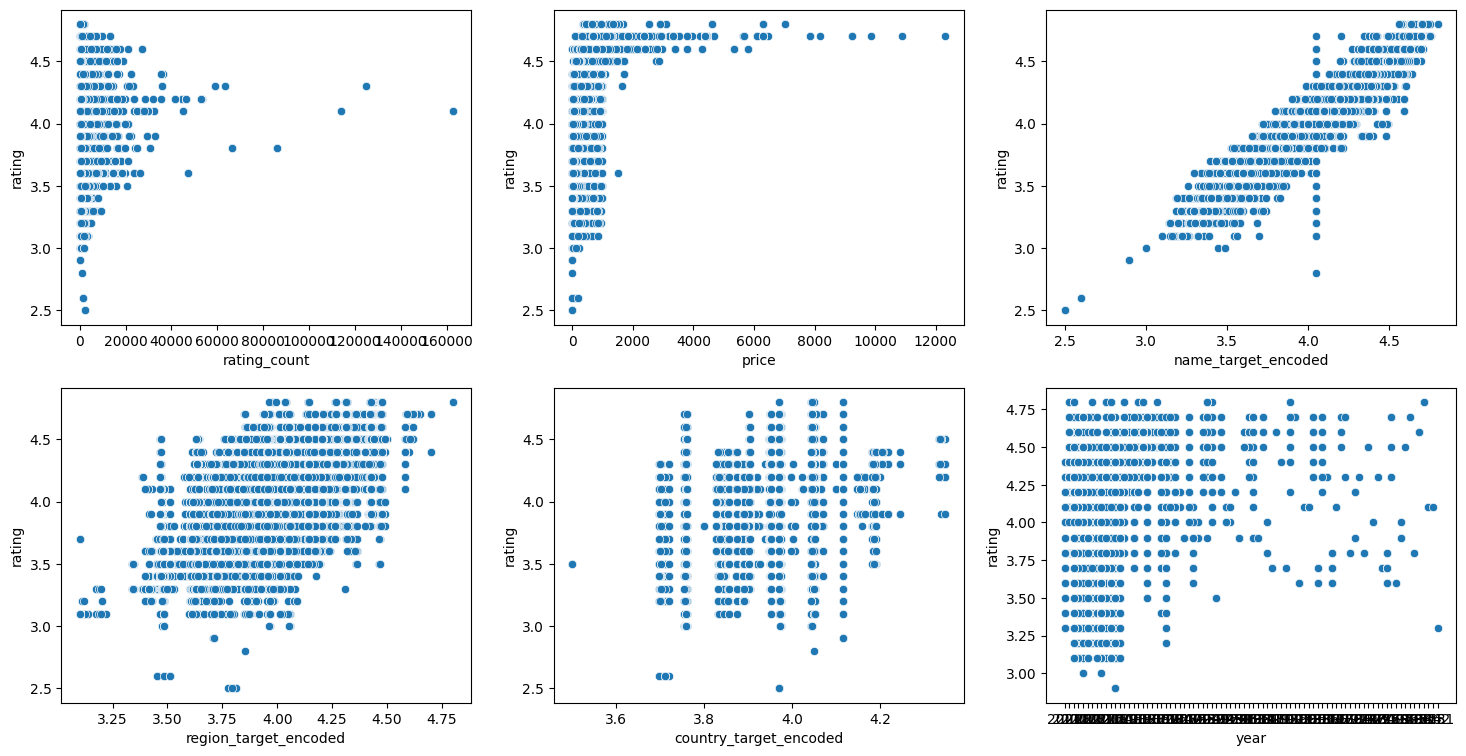

In [ ]:
fig, axis = plt.subplots(2, 3, figsize=(18, 9))
axis = axis.flatten()
for i, col in enumerate(['rating_count',	'price',	'name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'year']):
  sns.scatterplot(x=X_train[col], y=y_train, ax=axis[i])
plt.show()

For the rating_count and price columns, we will apply a logarithmic transformation to make the relationship between them more linear.

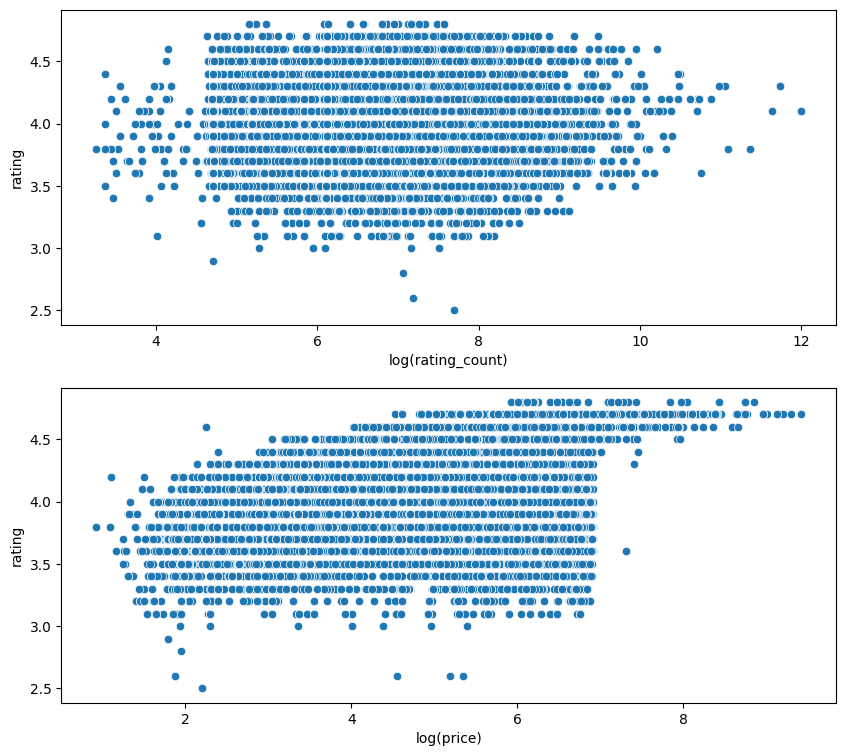

In [ ]:
fig, axis = plt.subplots(2, 1, figsize=(10, 9))
sns.scatterplot(x=np.log1p(X_train['rating_count']), y=y_train, ax=axis[0])
sns.scatterplot(x=np.log1p(X_train['price']), y=y_train, ax=axis[1])
axis[0].set_xlabel('log(rating_count)')
axis[1].set_xlabel('log(price)')
plt.show()


For rating_count, there is no clear relationship with the wine rating.

The wine rating slightly increases as the price increases. We can also see that for premium wines, the rating does not fall below 4.2.

In [ ]:
X_train['log_rating_count'] = np.log1p(X_train['rating_count'])
X_train['log_price'] = np.log1p(X_train['price'])
X_test['log_rating_count'] = np.log1p(X_test['rating_count'])
X_test['log_price'] = np.log1p(X_test['price'])

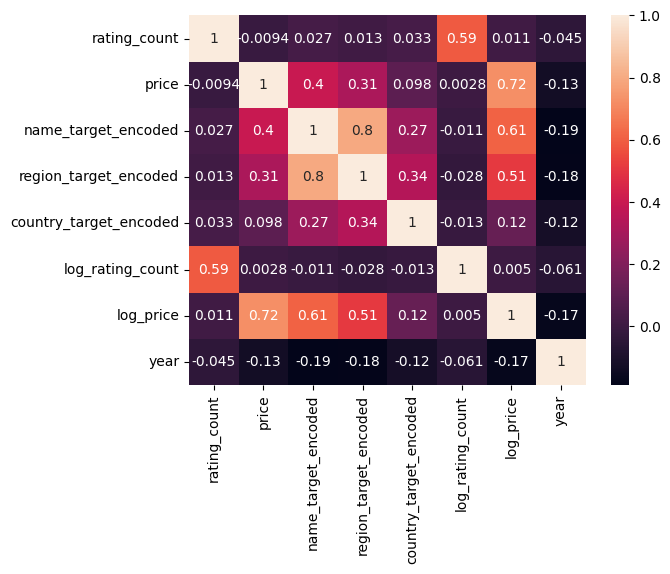

In [ ]:
sns.heatmap(X_train[['rating_count',	'price','name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'log_rating_count', 'log_price', 'year']].corr(), annot=True)
plt.show()

There is a strong correlation between region and producer, as well as between country and both region and producer. For linear regression, we will probably choose only one of the columns — either name or region — because linear regression assumes that variables are independent from each other.

Price depends on both the region and the producer.

log_price is highly correlated with name_target_encoded and region_target_encoded.d

## Division into training and test sets

In [ ]:
from sklearn.tree import DecisionTreeRegressor, plot_tree

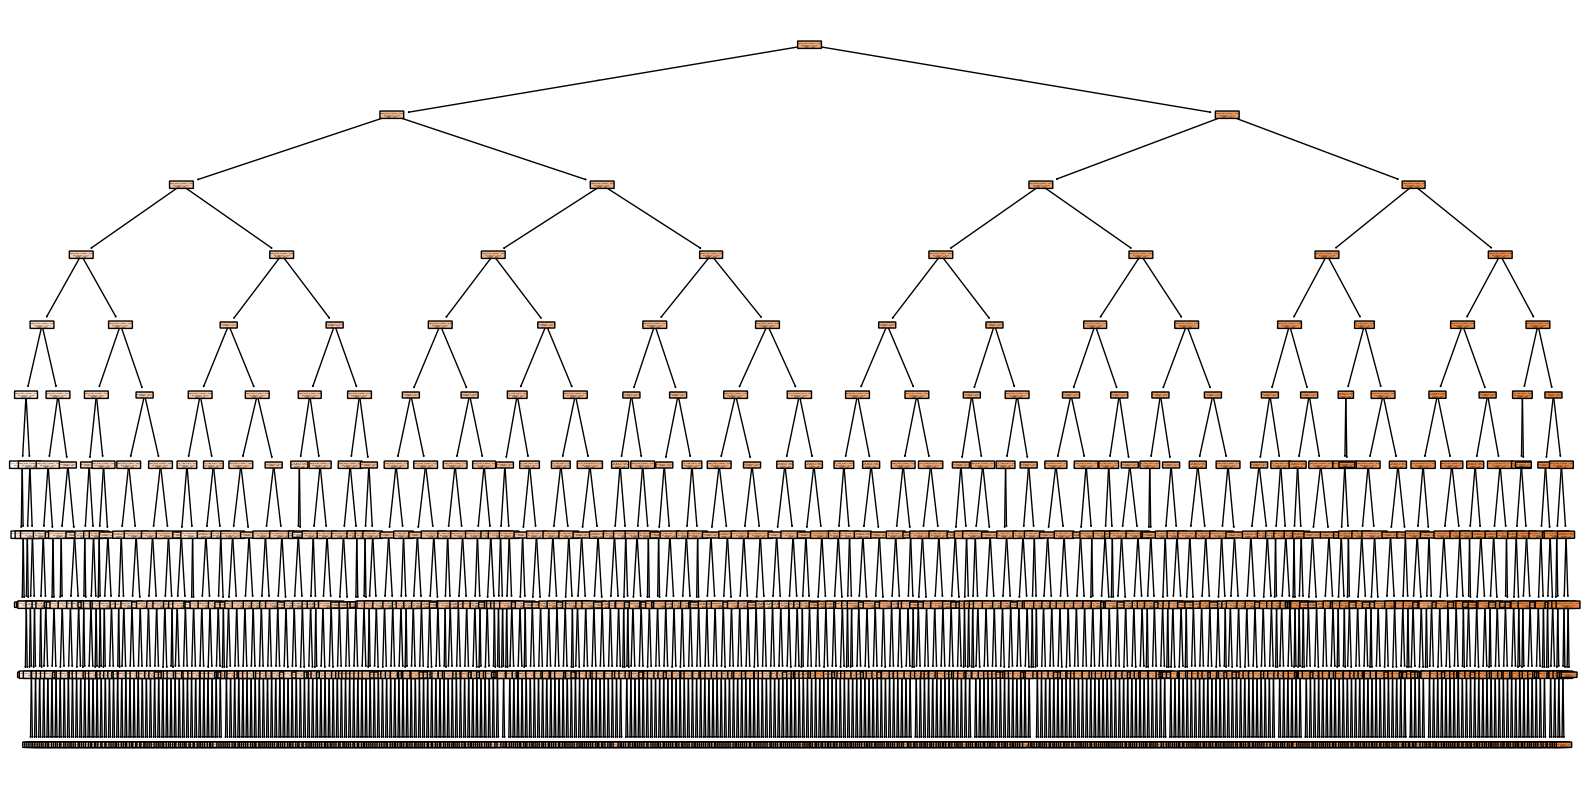

In [ ]:
dt1 = DecisionTreeRegressor(max_depth=10)
dt1.fit(X_train[['name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'log_rating_count', 'log_price', 'year']], y_train)
y_pred_dt1 = dt1.predict(X_test[['name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'log_rating_count', 'log_price', 'year']])
fig, ax = plt.subplots(figsize=(20, 10))

plot_tree(dt1, feature_names=['name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'log_rating_count', 'log_price', 'year'], filled=True, rounded=True, ax=ax,)

plt.savefig('decisionTree1.png', dpi=600)
plt.show()

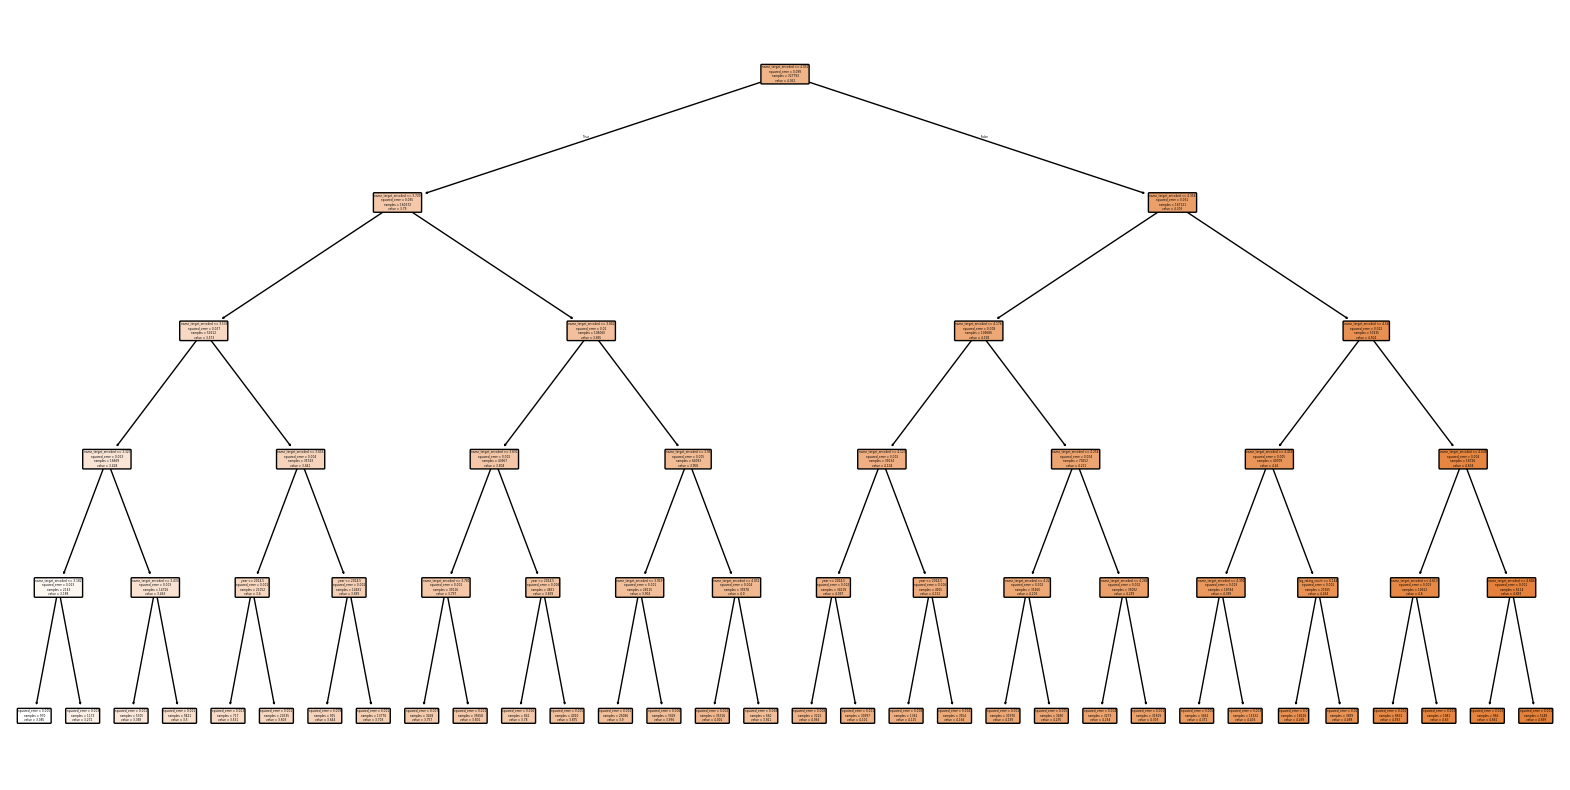

In [ ]:
dt2 = DecisionTreeRegressor(max_depth=5)
dt2.fit(X_train[['name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'log_rating_count', 'log_price', 'year']], y_train)
y_pred_dt2 = dt2.predict(X_test[['name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'log_rating_count', 'log_price', 'year']])
fig, ax = plt.subplots(figsize=(20, 10))

plot_tree(dt2, feature_names=['name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'log_rating_count', 'log_price', 'year'], filled=True, rounded=True, ax=ax,)

plt.savefig('decisionTree2.png', dpi=600)
plt.show()

# Regresja liniowa


In [ ]:
cols_lr = ['log_rating_count', 'log_price', 'year', 'non_vintage', 'name_target_encoded', 'country_target_encoded', 'region_target_encoded']
# X_lr = X[['log_rating_count', 'log_price', 'year', 'non_vintage', 'name_target_encoded', 'country_target_encoded', 'region_target_encoded']]
# X_lr_no_year = df[['log_rating_count', 'log_price', 'non_vintage', 'name_target_encoded', 'country_target_encoded', 'region_target_encoded']]
# X_lr_with_year = df.loc[df['year'].notna(), ['log_rating_count', 'log_price', 'year', 'name_target_encoded', 'country_target_encoded', 'region_target_encoded']]
# y = df['rating']
# y_lr_with_year = df.loc[df['year'].notna(),['rating']]
# X_lr_train, X_lr_test, y_lr_lr_train, y_lr_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_lr_no_year_train, X_lr_no_year_test, y_lr_no_year_train, y_lr_no_year_test = X_train[cols_lr].drop('year', axis=1), X_test[cols_lr].drop('year', axis=1), y_train, y_test
X_lr_with_year_train, X_lr_with_year_test, y_lr_with_year_train, y_lr_with_year_test = X_train.loc[X_train['year'].notna(), cols_lr].drop('non_vintage', axis=1), X_test.loc[X_test['year'].notna(), cols_lr].drop('non_vintage', axis=1), y_train[X_train['year'].notna()], y_test[X_test['year'].notna()]

In [ ]:
from sklearn.linear_model import LinearRegression

In [ ]:
lr = LinearRegression()
lr.fit(X_lr_no_year_train.drop(['country_target_encoded', 'region_target_encoded'], axis=1), y_lr_no_year_train)

y_lr_pred = lr.predict(X_lr_no_year_test.drop(['country_target_encoded', 'region_target_encoded'], axis=1))
lr.coef_

array([-7.91788133e-05, -5.07525827e-04, -7.14006614e-04,  1.00107597e+00])

In [ ]:
lr.feature_names_in_

array(['log_rating_count', 'log_price', 'non_vintage',
       'name_target_encoded'], dtype=object)

In [ ]:
lr_with_year = LinearRegression()
lr_with_year.fit(X_lr_with_year_train, y_lr_with_year_train)

y_lr_with_year_pred = lr_with_year.predict(X_lr_with_year_test)

In [ ]:
lr.coef_

array([-7.91788133e-05, -5.07525827e-04, -7.14006614e-04,  1.00107597e+00])

In [ ]:
lr.feature_names_in_

array(['log_rating_count', 'log_price', 'non_vintage',
       'name_target_encoded'], dtype=object)

## Conclusions

rating is strongly dependent on name_target_encoded, while the other explanatory variables are not significant in estimating the rating.

Conclusion: the wine rating mainly depends on the producer

## Model evaluation

In [ ]:
from sklearn.metrics import mean_squared_error

In [ ]:
print('MSE for LinearRegresion: ', mean_squared_error(y_lr_pred, y_lr_no_year_test))

MSE for LinearRegresion:  0.001794236883451429


The results seem suspiciously good.

In [ ]:
print('MSE for LiniarRegresion: ', mean_squared_error(y_lr_with_year_pred, y_lr_with_year_test))

MSE for LiniarRegresion:  0.0020031061351145686


The model also achieves very good results

In [ ]:
print('MSE for LiniarRegresion: ', mean_squared_error(y_lr_with_year_pred, y_lr_with_year_test))

MSE for LiniarRegresion:  0.0020031061351145686


Decision Tree Regressor 1

In [ ]:
print('MSE for DecisionTree: ', mean_squared_error(y_pred_dt1, y_test))

MSE for DecisionTree:  0.0011523711687954582


Decision Tree Regressor 2

In [ ]:
print('MSE for DecisionTree: ', mean_squared_error(y_pred_dt2, y_test))

MSE for DecisionTree:  0.0018326989744853676


Model 1 performs better because it has a greater depth

In [ ]:
for importance, name in sorted(zip(dt1.feature_importances_, ['name_target_encoded',	'region_target_encoded',	'country_target_encoded', 'log_rating_count', 'log_price', 'year']),reverse=True)[:5]:
    print (name, importance)

name_target_encoded 0.9926935722256037
year 0.0030846306959920098
log_rating_count 0.0016868180907310374
log_price 0.001194913157793413
region_target_encoded 0.0008377357711053448


# Summary

In general, we can see that the wine rating mainly depends on the producer’s average rating, while the other variables have only a small impact. In particular, price does not strongly translate into a better rating, except for the group of luxury wines.

Therefore, we propose selecting the best producers based on the following criteria:
- the highest average rating
- more than 100 ratings
- and the lowest price

# Ranking popularności

In [ ]:
df.groupby('name')['rating_count'].sum().sort_values(ascending=False).head(10)

,rating_count
name,
Veuve Clicquot Brut (Carte Jaune) Champagne N.V.,45960629
Mo t & Chandon Imprial Brut Champagne N.V.,40854725
Bollinger Special Cuve Brut A Champagne N.V.,20979080
Farnese Edizione Cinque Autoctoni N.V.,15991920
Taittinger Brut (Rserve) Champagne N.V.,14464678
Casal Garcia Vinho Verde N.V.,14219700
Louis Roederer Brut Premier Champagne N.V.,13104050
Perrier-Jou t Grand Brut Champagne N.V.,12812610
Laurent-Perrier La Cuve Brut Champagne N.V.,12640368


In [ ]:
df[(df['rating'] >= 4.2) & (df['price'] <= df['price'].median()) & (df['rating_count'] >= 100)] \
  .groupby('name')[['rating','price']].mean().sort_values('rating', ascending=False).head(20)

,rating,price
name,,
Rutini Apartado Gran Malbec,4.600000,8.500000
Cartuxa PTMra-Manca Branco,4.600000,54.920000
El Enemigo Gran Enemigo,4.600000,55.613636
Belondrade Belondrade y Lurton,4.500000,42.187137
Antinori Castello della Sala Cervaro della Sala,4.500000,51.596256
Tenuta Ulisse Limited Edition 10 Vendemmie N.V.,4.500000,30.114848
Casa Ferreirinha Quinta da Leda Douro,4.500000,45.505807
Bodegas Valduero Ribera Del Duero Reserva Premium 6 Anos,4.500000,49.590000
Austin Hope Paso Robles Cabernet Sauvignon,4.500000,46.980000


##Summary
Wine quality depends mainly on producer reputation and number of reviews. Price alone does not guarantee a high rating.
Popularity Ranking
The most popular brands are mainly champagne producers such as:

- Veuve Clicquot

- Moët & Chandon

- Bollinger

- Taittinger

Best Wines Criteria
Selected wines meet these conditions:

- Rating ≥ 4.2

- At least 100 reviews

- Price below median

Conclusion
The project demonstrates:

- Data Cleaning

- EDA

- Feature Engineering

- Machine Learning in Python

